## Checkpoint 2 — 1CCPO

### Integrantes
- Nome: Vinicius Sanches Chiarle RM:568846
        Mateus Felipe Curtale Serafim RM:571129

## Objetivo

Esta atividade possui duas tarefas independentes:

1. Classificar a fonte renovável de empreendimentos usando dados públicos da ANEEL.
2. Estimar a radiação solar horária em Petrolina (PE) usando dados históricos da API Open-Meteo.

Em cada tarefa são comparados três algoritmos diferentes, totalizando seis modelos.



# 1. Bibliotecas


In [1]:
import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


# 2. Tarefa 1 — Classificação da fonte renovável

Fonte: SIGA — ANEEL.

O modelo utilizará somente `potencia_kw`, `latitude` e `longitude`.

O alvo será:

- UFV → Solar
- EOL → Eólica
- UHE, PCH e CGH → Hidráulica

A coluna que contém a sigla original não será usada como entrada do modelo.


In [3]:
import pandas as pd
import requests
from io import BytesIO

ANEEL_URL = (
    "https://dadosabertos.aneel.gov.br/dataset/"
    "6d90b77c-c5f5-4d81-bdec-7bc619494bb9/resource/"
    "11ec447d-698d-4ab8-977f-b424d5deee6a/download/"
    "siga-empreendimentos-geracao.csv"
)

def baixar_aneel(url):
    resposta = requests.get(url, timeout=60)
    resposta.raise_for_status()

    arquivo = BytesIO(resposta.content)

    # O CSV da ANEEL pode usar ; como separador.
    # Tentamos primeiro ; e depois ,.
    try:
        df = pd.read_csv(
            arquivo,
            sep=";",
            encoding="utf-8-sig",
            low_memory=False
        )

        # Se ficou praticamente tudo em uma coluna,
        # tenta vírgula.
        if len(df.columns) <= 2:
            arquivo.seek(0)
            df = pd.read_csv(
                arquivo,
                sep=",",
                encoding="utf-8-sig",
                low_memory=False
            )

    except Exception:
        arquivo.seek(0)

        df = pd.read_csv(
            arquivo,
            sep=",",
            encoding="utf-8-sig",
            low_memory=False
        )

    return df


# Baixar os dados
aneel_raw = baixar_aneel(ANEEL_URL)

print("Dimensão original:", aneel_raw.shape)
print("\nColunas encontradas:")
print(aneel_raw.columns.tolist())

Dimensão original: (25045, 23)

Colunas encontradas:
['DatGeracaoConjuntoDados', 'NomEmpreendimento', 'IdeNucleoCEG', 'CodCEG', 'SigUFPrincipal', 'SigTipoGeracao', 'DscFaseUsina', 'DscOrigemCombustivel', 'DscFonteCombustivel', 'DscTipoOutorga', 'NomFonteCombustivel', 'DatEntradaOperacao', 'MdaPotenciaOutorgadaKw', 'MdaPotenciaFiscalizadaKw', 'MdaGarantiaFisicaKw', 'IdcGeracaoQualificada', 'NumCoordNEmpreendimento', 'NumCoordEEmpreendimento', 'DatInicioVigencia', 'DatFimVigencia', 'DscPropriRegimePariticipacao', 'DscSubBacia', 'DscMuninicpios']


In [4]:
colunas_necessarias = [
    "MdaPotenciaOutorgadaKw",
    "NumCoordNEmpreendimento",
    "NumCoordEEmpreendimento",
    "SigTipoGeracao"
]

faltantes = [
    coluna for coluna in colunas_necessarias
    if coluna not in aneel_raw.columns
]

if faltantes:
    raise RuntimeError(
        f"As seguintes colunas não foram encontradas: {faltantes}"
    )

aneel = aneel_raw[colunas_necessarias].copy()

aneel = aneel.rename(columns={
    "MdaPotenciaOutorgadaKw": "potencia_kw",
    "NumCoordNEmpreendimento": "latitude",
    "NumCoordEEmpreendimento": "longitude",
    "SigTipoGeracao": "fonte_original"
})

for coluna in ["potencia_kw", "latitude", "longitude"]:
    aneel[coluna] = (
        aneel[coluna]
        .astype(str)
        .str.replace(",", ".", regex=False)
        .str.strip()
    )

    aneel[coluna] = pd.to_numeric(
        aneel[coluna],
        errors="coerce"
    )

def classificar_fonte(tipo):
    if pd.isna(tipo):
        return None

    tipo = str(tipo).strip().upper()

    if tipo == "UFV":
        return "Solar"

    elif tipo == "EOL":
        return "Eólica"

    elif tipo in ["UHE", "PCH", "CGH"]:
        return "Hidráulica"

    return None


aneel["fonte"] = aneel["fonte_original"].apply(classificar_fonte)

aneel = aneel.dropna(
    subset=[
        "potencia_kw",
        "latitude",
        "longitude",
        "fonte"
    ]
)

aneel = aneel[
    aneel["fonte"].isin([
        "Solar",
        "Eólica",
        "Hidráulica"
    ])
].copy()

aneel_final = aneel[
    [
        "potencia_kw",
        "latitude",
        "longitude",
        "fonte"
    ]
].copy()

print("\nDimensão final:", aneel_final.shape)

print("\nDistribuição das classes:")
print(aneel_final["fonte"].value_counts())

print("\nValores ausentes:")
print(aneel_final.isnull().sum())

aneel_final.to_csv(
    "aneel_classificacao_orange.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCSV criado com sucesso:")
print("aneel_classificacao_orange.csv")

display(aneel_final.head())


Dimensão final: (21987, 4)

Distribuição das classes:
fonte
Solar         18962
Eólica         1549
Hidráulica     1476
Name: count, dtype: int64

Valores ausentes:
potencia_kw    0
latitude       0
longitude      0
fonte          0
dtype: int64

CSV criado com sucesso:
aneel_classificacao_orange.csv


,potencia_kw,latitude,longitude,fonte
0,1400.0,-20.124799,-43.870202,Hidráulica
1,3972.0,-20.131873,-43.876935,Hidráulica
2,1440.0,-20.137545,-43.891926,Hidráulica
3,100000.0,-29.064753,-51.674942,Hidráulica
4,720.0,-27.823775,-52.069997,Hidráulica


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

X = aneel_final[
    [
        "potencia_kw",
        "latitude",
        "longitude"
    ]
]

y = aneel_final["fonte"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


modelos = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )
}

resultados = []

for nome, modelo in modelos.items():

    modelo.fit(X_train, y_train)

    previsoes = modelo.predict(X_test)

    resultados.append({
        "Algoritmo": nome,
        "Accuracy": accuracy_score(y_test, previsoes),
        "Precision (macro)": precision_score(
            y_test,
            previsoes,
            average="macro",
            zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test,
            previsoes,
            average="macro",
            zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_test,
            previsoes,
            average="macro",
            zero_division=0
        )
    })

    print("\n" + "=" * 60)
    print(nome)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            previsoes,
            zero_division=0
        )
    )

    print("Matriz de confusão:")
    print(confusion_matrix(y_test, previsoes))


resultado_classificacao = pd.DataFrame(resultados)

display(resultado_classificacao)


Regressão Logística
              precision    recall  f1-score   support

      Eólica       0.38      0.04      0.07       310
  Hidráulica       0.65      0.45      0.53       295
       Solar       0.90      0.99      0.94      3793

    accuracy                           0.88      4398
   macro avg       0.64      0.49      0.51      4398
weighted avg       0.84      0.88      0.85      4398

Matriz de confusão:
[[  12   30  268]
 [   4  132  159]
 [  16   40 3737]]

KNN
              precision    recall  f1-score   support

      Eólica       0.92      0.92      0.92       310
  Hidráulica       0.88      0.88      0.88       295
       Solar       0.99      0.99      0.99      3793

    accuracy                           0.97      4398
   macro avg       0.93      0.93      0.93      4398
weighted avg       0.97      0.97      0.97      4398

Matriz de confusão:
[[ 284    3   23]
 [   3  260   32]
 [  22   33 3738]]

Random Forest
              precision    recall  f1-score   s

,Algoritmo,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Regressão Logística,0.882447,0.641973,0.490468,0.513554
1,KNN,0.973624,0.927657,0.927662,0.927658
2,Random Forest,0.983629,0.948707,0.963999,0.956054


In [6]:
mapa_fonte = {
    "UFV": "Solar",
    "EOL": "Eólica",
    "UHE": "Hidráulica",
    "PCH": "Hidráulica",
    "CGH": "Hidráulica"
}

colunas_aneel = [
    "MdaPotenciaOutorgadaKw",
    "NumCoordNEmpreendimento",
    "NumCoordEEmpreendimento",
    "SigTipoGeracao"
]

faltantes = [c for c in colunas_aneel if c not in aneel_raw.columns]
if faltantes:
    raise KeyError(f"Colunas esperadas não encontradas na resposta da ANEEL: {faltantes}")

aneel = aneel_raw[colunas_aneel].copy()

aneel = aneel.rename(columns={
    "MdaPotenciaOutorgadaKw": "potencia_kw",
    "NumCoordNEmpreendimento": "latitude",
    "NumCoordEEmpreendimento": "longitude",
    "SigTipoGeracao": "sigla_fonte"
})

aneel["fonte"] = aneel["sigla_fonte"].astype(str).str.strip().map(mapa_fonte)

for c in ["potencia_kw", "latitude", "longitude"]:
    aneel[c] = pd.to_numeric(
        aneel[c].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

aneel_classificacao_orange = (
    aneel[["potencia_kw", "latitude", "longitude", "fonte"]]
    .dropna()
    .reset_index(drop=True)
)

aneel_classificacao_orange.to_csv(
    "aneel_classificacao_orange.csv",
    index=False,
    encoding="utf-8"
)

print("CSV criado: aneel_classificacao_orange.csv")
print("Linhas:", len(aneel_classificacao_orange))
display(aneel_classificacao_orange.head())


CSV criado: aneel_classificacao_orange.csv
Linhas: 21987


,potencia_kw,latitude,longitude,fonte
0,1400.0,-20.124799,-43.870202,Hidráulica
1,3972.0,-20.131873,-43.876935,Hidráulica
2,1440.0,-20.137545,-43.891926,Hidráulica
3,100000.0,-29.064753,-51.674942,Hidráulica
4,720.0,-27.823775,-52.069997,Hidráulica


## 2.1 Exploração


In [7]:
print("Quantidade de linhas:", len(aneel_classificacao_orange))
print("\nValores ausentes:")
display(aneel_classificacao_orange.isna().sum())

print("\nDistribuição das classes:")
display(aneel_classificacao_orange["fonte"].value_counts())

print("\nEstatísticas:")
display(aneel_classificacao_orange[["potencia_kw","latitude","longitude"]].describe())


Quantidade de linhas: 21987

Valores ausentes:


,0
potencia_kw,0
latitude,0
longitude,0
fonte,0



Distribuição das classes:


,count
fonte,
Solar,18962
Eólica,1549
Hidráulica,1476



Estatísticas:


,potencia_kw,latitude,longitude
count,2.198700e+04,21987.000000,21987.000000
mean,1.179152e+04,-7.295947,-49.023751
std,1.282592e+05,7.848751,8.558610
min,1.000000e-02,-33.722806,-72.250020
25%,1.000000e+00,-13.293318,-52.495189
50%,1.000000e+00,-2.419570,-50.726635
75%,3.600000e+02,-1.888273,-49.746351
max,1.123310e+07,4.490711,0.000000


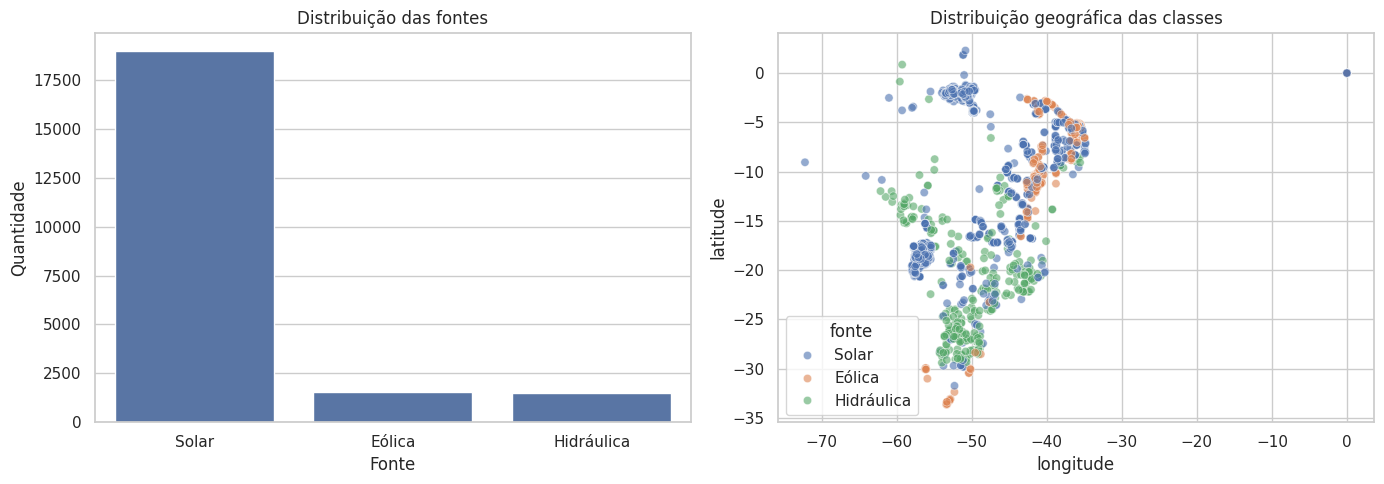

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=aneel_classificacao_orange,
    x="fonte",
    order=aneel_classificacao_orange["fonte"].value_counts().index,
    ax=axes[0]
)
axes[0].set_title("Distribuição das fontes")
axes[0].set_xlabel("Fonte")
axes[0].set_ylabel("Quantidade")

sns.scatterplot(
    data=aneel_classificacao_orange.sample(
        min(5000, len(aneel_classificacao_orange)),
        random_state=RANDOM_STATE
    ),
    x="longitude",
    y="latitude",
    hue="fonte",
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title("Distribuição geográfica das classes")

plt.tight_layout()
plt.show()


## 2.2 Treino e teste

A divisão é 80%/20%, com `random_state=42` e estratificação para manter a proporção das três classes.


In [9]:
X = aneel_classificacao_orange[["potencia_kw", "latitude", "longitude"]]
y = aneel_classificacao_orange["fonte"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)


Treino: (17589, 3)
Teste: (4398, 3)


## 2.3 Três classificadores

Foram utilizados:

1. Regressão Logística — com padronização.
2. KNN — com padronização.
3. Random Forest — sem padronização.

A padronização, quando utilizada, fica dentro do `Pipeline`, portanto é ajustada somente com os dados de treino.


In [10]:
classificadores = {
    "Regressão Logística": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    )
}

resultados_clf = []
predicoes_clf = {}

for nome, modelo in classificadores.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    predicoes_clf[nome] = pred

    resultados_clf.append({
        "Algoritmo": nome,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })

resultados_clf = pd.DataFrame(resultados_clf).sort_values(
    "F1_macro", ascending=False
).reset_index(drop=True)

print("Métricas multiclasses usando média MACRO:")
display(resultados_clf)


Métricas multiclasses usando média MACRO:


,Algoritmo,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Random Forest,0.983629,0.948707,0.963999,0.956054
1,KNN,0.973624,0.927657,0.927662,0.927658
2,Regressão Logística,0.882447,0.641973,0.490468,0.513554


## 2.4 Matrizes de confusão


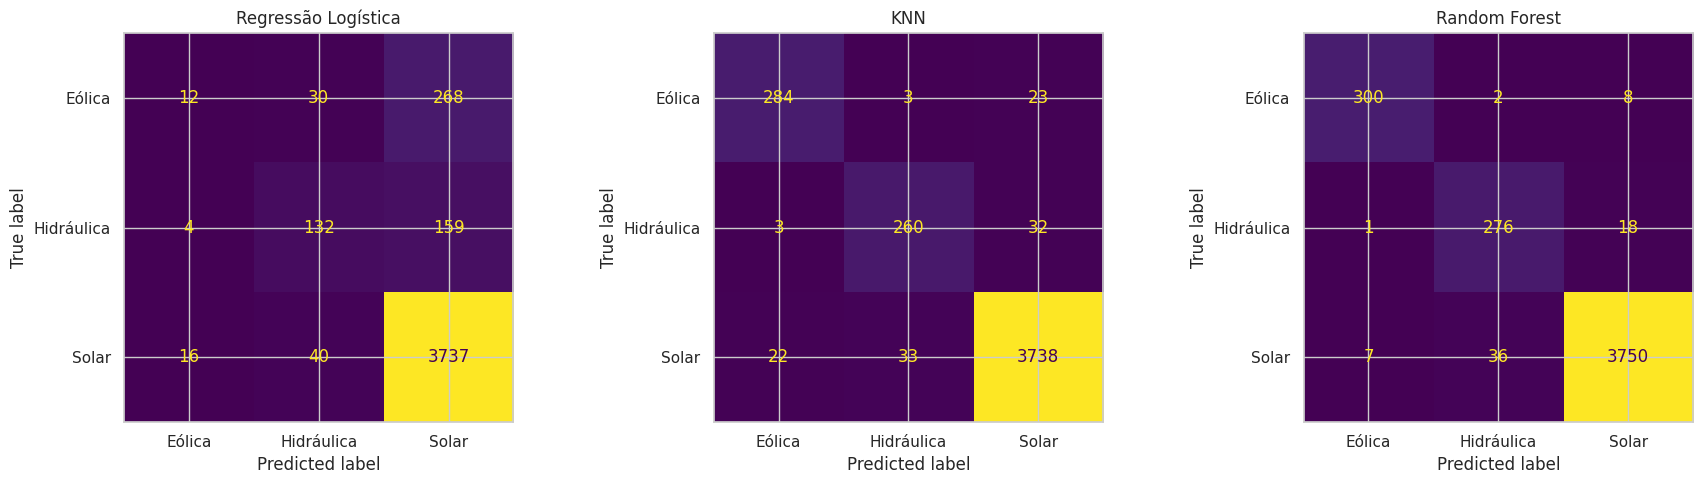

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

classes = sorted(y.unique())

for ax, (nome, pred) in zip(axes, predicoes_clf.items()):
    cm = confusion_matrix(y_test, pred, labels=classes)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(nome)

plt.tight_layout()
plt.show()


### Interpretação da classificação

As métricas utilizam média **macro**, dando o mesmo peso a cada uma das três classes.

A matriz de confusão mostra em quais classes ocorreram os erros. As confusões devem ser interpretadas considerando que o modelo recebe somente potência e localização.

Essa é uma limitação importante: empreendimentos de fontes diferentes podem ocupar regiões semelhantes e apresentar faixas de potência que se sobrepõem. Portanto, localização e potência podem ajudar na classificação, mas não identificam necessariamente a tecnologia de geração.


In [12]:
print("Resumo automático:")
print(resultados_clf.to_string(index=False))

melhor_clf = resultados_clf.iloc[0]["Algoritmo"]
print(f"\nMaior F1 macro nesta execução: {melhor_clf}.")
print("Isso não significa que potência e localização sejam suficientes para identificar a fonte em todos os empreendimentos.")


Resumo automático:
          Algoritmo  Accuracy  Precision_macro  Recall_macro  F1_macro
      Random Forest  0.983629         0.948707      0.963999  0.956054
                KNN  0.973624         0.927657      0.927662  0.927658
Regressão Logística  0.882447         0.641973      0.490468  0.513554

Maior F1 macro nesta execução: Random Forest.
Isso não significa que potência e localização sejam suficientes para identificar a fonte em todos os empreendimentos.


# 3. Tarefa 2 — Regressão da radiação solar

Fonte: API histórica **Open-Meteo**.

Local: Petrolina (PE), aproximadamente:

- latitude: -9,39
- longitude: -40,50
- período: 01/04/2025 a 30/06/2025
- fuso: `America/Recife`
- horas utilizadas: 7h até 17h

A variável alvo é `radiacao_w_m2`.


In [13]:
OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": -9.39,
    "longitude": -40.50,
    "start_date": "2025-04-01",
    "end_date": "2025-06-30",
    "hourly": "temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m,shortwave_radiation",
    "timezone": "America/Recife"
}

r = requests.get(OPEN_METEO_URL, params=params, timeout=90)
r.raise_for_status()
meteo_json = r.json()

print("Resposta recebida.")
print("Chaves:", meteo_json.keys())


Resposta recebida.
Chaves: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [14]:
hourly = meteo_json["hourly"]

meteo = pd.DataFrame({
    "data_hora": pd.to_datetime(hourly["time"]),
    "temperatura_c": hourly["temperature_2m"],
    "umidade_pct": hourly["relative_humidity_2m"],
    "nuvens_pct": hourly["cloud_cover"],
    "vento_kmh": hourly["wind_speed_10m"],
    "radiacao_w_m2": hourly["shortwave_radiation"]
})

meteo["hora"] = meteo["data_hora"].dt.hour

meteo = meteo[
    (meteo["hora"] >= 7) &
    (meteo["hora"] <= 17)
].copy()

meteo = meteo.sort_values("data_hora").reset_index(drop=True)

meteo.to_csv(
    "meteo_regressao_orange.csv",
    index=False,
    encoding="utf-8"
)

print("CSV criado: meteo_regressao_orange.csv")
print("Dimensão:", meteo.shape)
display(meteo.head())


CSV criado: meteo_regressao_orange.csv
Dimensão: (1001, 7)


,data_hora,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,radiacao_w_m2,hora
0,2025-04-01 07:00:00,25.3,74,100,17.7,116.0,7
1,2025-04-01 08:00:00,26.5,66,100,18.1,269.0,8
2,2025-04-01 09:00:00,28.4,55,97,18.0,529.0,9
3,2025-04-01 10:00:00,30.8,44,21,18.4,797.0,10
4,2025-04-01 11:00:00,32.7,36,26,20.1,880.0,11


## 3.1 Exploração da regressão


In [15]:
print("Valores ausentes:")
display(meteo.isna().sum())

print("\nEstatísticas:")
display(meteo[[
    "temperatura_c",
    "umidade_pct",
    "nuvens_pct",
    "vento_kmh",
    "hora",
    "radiacao_w_m2"
]].describe())


Valores ausentes:


,0
data_hora,0
temperatura_c,0
umidade_pct,0
nuvens_pct,0
vento_kmh,0
radiacao_w_m2,0
hora,0



Estatísticas:


,temperatura_c,umidade_pct,nuvens_pct,vento_kmh,hora,radiacao_w_m2
count,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000,1001.000000
mean,28.885914,50.544456,55.108891,15.465435,12.000000,472.854146
std,3.656514,15.913965,37.851461,4.923631,3.163858,256.368950
min,19.500000,21.000000,0.000000,2.300000,7.000000,13.000000
25%,26.300000,38.000000,19.000000,12.200000,9.000000,250.000000
50%,29.100000,49.000000,54.000000,15.400000,12.000000,466.000000
75%,31.700000,61.000000,98.000000,19.000000,15.000000,696.000000
max,36.100000,95.000000,100.000000,30.100000,17.000000,1002.000000


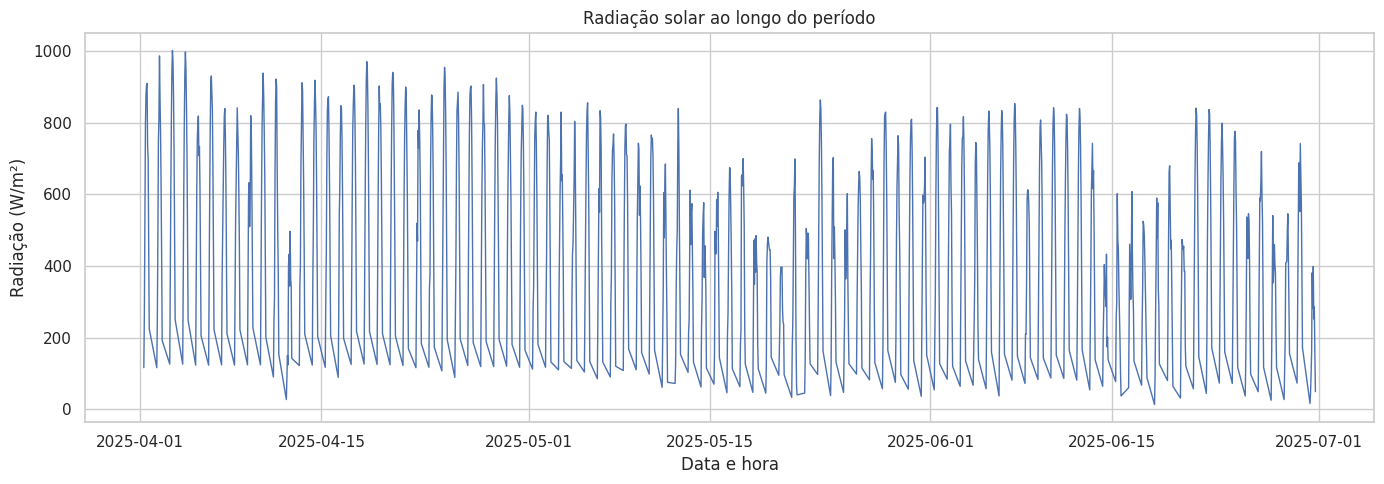

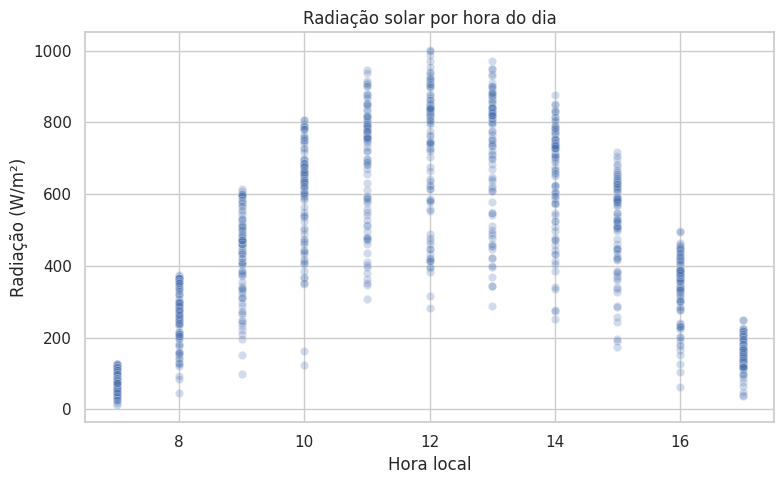

In [16]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(meteo["data_hora"], meteo["radiacao_w_m2"], linewidth=1)
ax.set_title("Radiação solar ao longo do período")
ax.set_xlabel("Data e hora")
ax.set_ylabel("Radiação (W/m²)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=meteo, x="hora", y="radiacao_w_m2", alpha=0.25, ax=ax)
ax.set_title("Radiação solar por hora do dia")
ax.set_xlabel("Hora local")
ax.set_ylabel("Radiação (W/m²)")
plt.tight_layout()
plt.show()


## 3.2 Definição de X e y e divisão temporal

As primeiras **80% das horas** são usadas para treino e as últimas **20%** para teste. A ordem temporal é preservada.

`data_hora` é usada para ordenar/separar os dados e não entra como variável explicativa.


In [17]:
features = [
    "temperatura_c",
    "umidade_pct",
    "nuvens_pct",
    "vento_kmh",
    "hora"
]

dados_reg = meteo.dropna(subset=features + ["radiacao_w_m2"]).copy()

X_reg = dados_reg[features]
y_reg = dados_reg["radiacao_w_m2"]

corte = int(len(dados_reg) * 0.80)

X_reg_train = X_reg.iloc[:corte].copy()
X_reg_test = X_reg.iloc[corte:].copy()

y_reg_train = y_reg.iloc[:corte].copy()
y_reg_test = y_reg.iloc[corte:].copy()

print("Treino:", X_reg_train.shape)
print("Teste:", X_reg_test.shape)
print("A ordem temporal foi preservada.")
print("Última data/hora do treino:", dados_reg["data_hora"].iloc[corte-1])
print("Primeira data/hora do teste:", dados_reg["data_hora"].iloc[corte])


Treino: (800, 5)
Teste: (201, 5)
A ordem temporal foi preservada.
Última data/hora do treino: 2025-06-12 14:00:00
Primeira data/hora do teste: 2025-06-12 15:00:00


## 3.3 Três regressores

Foram utilizados:

1. Regressão Linear
2. Random Forest Regressor
3. Gradient Boosting Regressor

Os três recebem exatamente a mesma divisão temporal.


In [18]:
regressores = {
    "Regressão Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LinearRegression())
    ]),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        random_state=RANDOM_STATE,
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3
    )
}

resultados_reg = []
predicoes_reg = {}

for nome, modelo in regressores.items():
    modelo.fit(X_reg_train, y_reg_train)
    pred = modelo.predict(X_reg_test)
    predicoes_reg[nome] = pred

    resultados_reg.append({
        "Algoritmo": nome,
        "MAE_W_m2": mean_absolute_error(y_reg_test, pred),
        "MSE_(W_m2)^2": mean_squared_error(y_reg_test, pred),
        "R2": r2_score(y_reg_test, pred)
    })

resultados_reg = pd.DataFrame(resultados_reg).sort_values(
    "MAE_W_m2", ascending=True
).reset_index(drop=True)

display(resultados_reg)


,Algoritmo,MAE_W_m2,MSE_(W_m2)^2,R2
0,Random Forest Regressor,66.399353,7210.083775,0.846323
1,Gradient Boosting Regressor,66.734097,7373.934464,0.842830
2,Regressão Linear,145.204885,30034.201092,0.359845


## 3.4 Valores reais × previstos


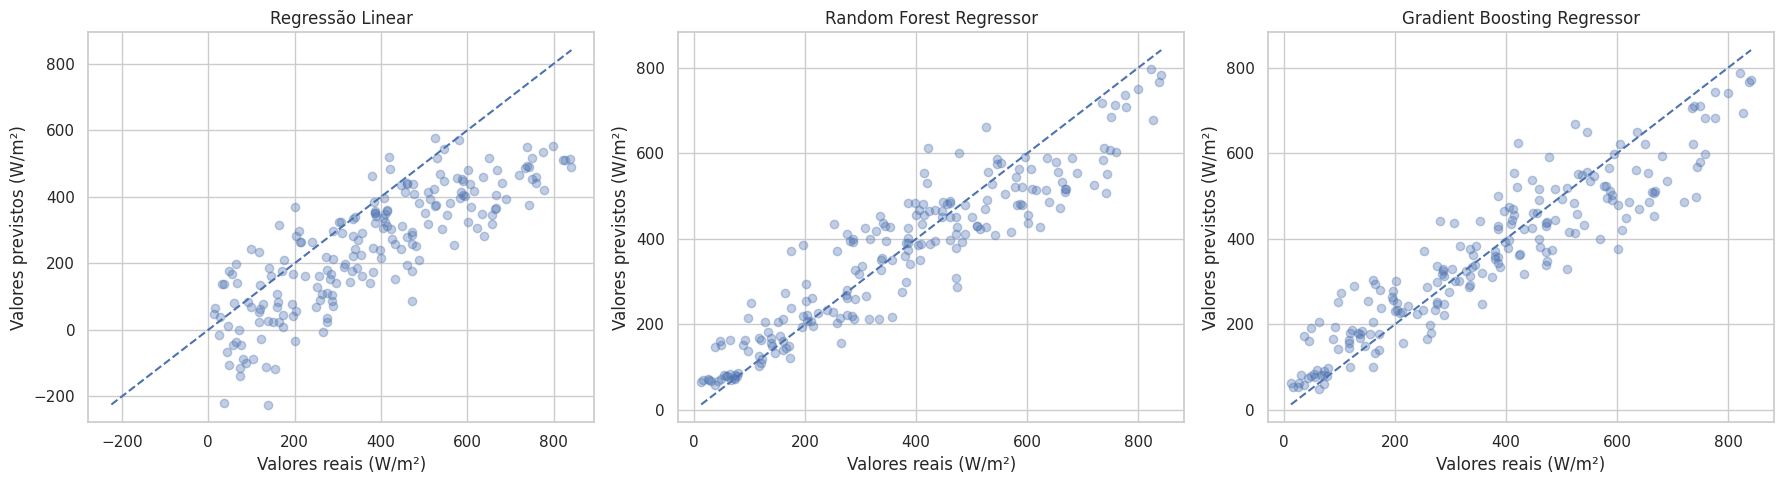

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nome, pred) in zip(axes, predicoes_reg.items()):
    ax.scatter(y_reg_test, pred, alpha=0.35)
    minimo = min(y_reg_test.min(), pred.min())
    maximo = max(y_reg_test.max(), pred.max())
    ax.plot([minimo, maximo], [minimo, maximo], linestyle="--")
    ax.set_title(nome)
    ax.set_xlabel("Valores reais (W/m²)")
    ax.set_ylabel("Valores previstos (W/m²)")

plt.tight_layout()
plt.show()


### Interpretação da regressão

A **hora do dia** é importante porque a radiação solar apresenta um ciclo diário: durante o período diurno a disponibilidade de radiação varia de acordo com a posição aparente do Sol.

Mesmo assim, a variável `radiacao_w_m2` representa radiação solar estimada/modelada. Ela **não equivale à geração elétrica** de um painel ou usina fotovoltaica, pois a geração depende também de potência instalada, área, eficiência dos módulos, orientação e inclinação, temperatura dos módulos, perdas elétricas, disponibilidade e outras características do sistema.


In [20]:
print("Comparação dos três regressores:")
display(resultados_reg)

melhor_reg = resultados_reg.iloc[0]["Algoritmo"]
print(f"Menor MAE nesta execução: {melhor_reg}.")
print("A escolha deve considerar conjuntamente MAE, MSE e R².")


Comparação dos três regressores:


,Algoritmo,MAE_W_m2,MSE_(W_m2)^2,R2
0,Random Forest Regressor,66.399353,7210.083775,0.846323
1,Gradient Boosting Regressor,66.734097,7373.934464,0.842830
2,Regressão Linear,145.204885,30034.201092,0.359845


Menor MAE nesta execução: Random Forest Regressor.
A escolha deve considerar conjuntamente MAE, MSE e R².


# 4. Conclusões

## Tarefa 1 — Classificação

A classificação foi realizada com potência outorgada e coordenadas geográficas. Foram comparados três algoritmos e as métricas multiclasses foram calculadas com média macro.

Os resultados devem ser interpretados considerando a limitação das entradas: potência e localização não são identificadores diretos da tecnologia de geração.

## Tarefa 2 — Regressão

A regressão utilizou temperatura, umidade, cobertura de nuvens, vento e hora. A separação foi temporal, usando as primeiras 80% das observações para treinamento e as últimas 20% para teste.

A radiação apresenta forte relação com o ciclo diário, mas estimar radiação solar não é o mesmo que prever geração elétrica de uma instalação fotovoltaica.

## Resultado final

As tabelas apresentadas no notebook identificam claramente os três algoritmos de cada tarefa e suas respectivas métricas.


In [21]:
print("=" * 70)
print("RESULTADOS FINAIS")
print("=" * 70)

print("\nCLASSIFICAÇÃO — métricas macro")
display(resultados_clf)

print("\nREGRESSÃO")
display(resultados_reg)

print("\nArquivos gerados:")
print("- aneel_classificacao_orange.csv")
print("- meteo_regressao_orange.csv")


RESULTADOS FINAIS

CLASSIFICAÇÃO — métricas macro


,Algoritmo,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Random Forest,0.983629,0.948707,0.963999,0.956054
1,KNN,0.973624,0.927657,0.927662,0.927658
2,Regressão Logística,0.882447,0.641973,0.490468,0.513554



REGRESSÃO


,Algoritmo,MAE_W_m2,MSE_(W_m2)^2,R2
0,Random Forest Regressor,66.399353,7210.083775,0.846323
1,Gradient Boosting Regressor,66.734097,7373.934464,0.842830
2,Regressão Linear,145.204885,30034.201092,0.359845



Arquivos gerados:
- aneel_classificacao_orange.csv
- meteo_regressao_orange.csv
